In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('EV_IoT_Telemetry_15000.csv')

In [6]:
# Create a copy for data cleaning
df_clean = df.copy()

# Check dataset dimensions
print("Number of rows and columns:", df.shape)

# Display column names
print("\nColumn names:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes)

# Display first 5 rows
print("\nFirst 5 observations:")
display(df.head())

Number of rows and columns: (15000, 29)

Column names:
['Timestamp', 'Vehicle_ID', 'Vehicle_Model', 'City', 'Operating_Mode', 'Vehicle_Speed_kmh', 'Distance_Since_Last_Record_km', 'Odometer_km', 'Ambient_Temperature_C', 'Ambient_Humidity_pct', 'Battery_SOC_pct', 'Battery_SOH_pct', 'Charge_Cycles', 'Battery_Pack_Voltage_V', 'Battery_Pack_Current_A', 'Battery_Temperature_C', 'Motor_RPM', 'Motor_Torque_Nm', 'Motor_Power_kW', 'Motor_Temperature_C', 'Motor_Vibration_g', 'Brake_Pressure_bar', 'Regenerative_Braking_Power_kW', 'Tire_Pressure_psi', 'Tire_Temperature_C', 'Battery_Power_kW', 'Component_Health_Score', 'Failure_Probability_pct', 'Maintenance_Alert']

Data types:
Timestamp                        datetime64[ns]
Vehicle_ID                               object
Vehicle_Model                            object
City                                     object
Operating_Mode                           object
Vehicle_Speed_kmh                       float64
Distance_Since_Last_Record_km        

,Timestamp,Vehicle_ID,Vehicle_Model,City,Operating_Mode,Vehicle_Speed_kmh,Distance_Since_Last_Record_km,Odometer_km,Ambient_Temperature_C,Ambient_Humidity_pct,...,Motor_Temperature_C,Motor_Vibration_g,Brake_Pressure_bar,Regenerative_Braking_Power_kW,Tire_Pressure_psi,Tire_Temperature_C,Battery_Power_kW,Component_Health_Score,Failure_Probability_pct,Maintenance_Alert
0,2025-01-01,EV_001,Compact,Pune,Idle,0.0,0.0,77040.96,19.48,63.79,...,35.32,0.102,0.57,0.0,33.10,18.89,0.96,0.8598,11.55,No
1,2025-01-01,EV_002,Sedan,Hyderabad,Idle,0.0,0.0,77329.26,24.22,70.94,...,33.46,0.096,0.37,0.0,35.70,28.27,0.63,0.9113,3.84,No
2,2025-01-01,EV_003,SUV,Mumbai,Idle,0.0,0.0,54060.45,27.48,57.42,...,41.69,0.109,0.51,0.0,33.60,28.49,1.31,0.9207,3.12,No
3,2025-01-01,EV_004,Compact,Pune,Charging,0.0,0.0,70126.55,20.64,78.29,...,32.39,0.091,0.34,0.0,33.84,23.86,-16.79,0.9215,3.07,No
4,2025-01-01,EV_005,Sedan,Hyderabad,Idle,0.0,0.0,74408.05,21.51,63.48,...,35.63,0.092,0.57,0.0,34.25,24.87,0.95,0.9212,3.09,No


Missing-value summary:


,Missing Values,Missing Percentage (%)
Vehicle_Speed_kmh,25,0.17
Ambient_Temperature_C,25,0.17
Ambient_Humidity_pct,25,0.17
Battery_SOC_pct,25,0.17
Battery_Pack_Current_A,25,0.17
Battery_Temperature_C,25,0.17
Motor_RPM,25,0.17
Motor_Temperature_C,25,0.17
Motor_Vibration_g,25,0.17
Tire_Pressure_psi,25,0.17


Total missing values: 329


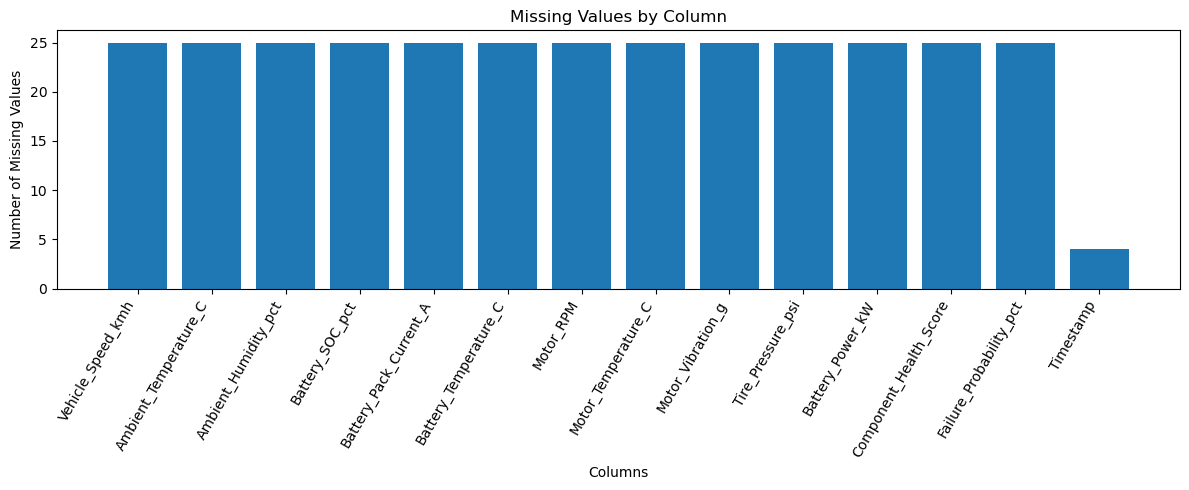

In [7]:
# Step 2: Check missing values

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing-value percentage
missing_percentage = (df.isnull().mean() * 100).round(2)

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage (%)": missing_percentage
})

# Display only columns containing missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Missing Values", ascending=False)

print("Missing-value summary:")
display(missing_summary)

print("Total missing values:", df.isnull().sum().sum())

# Graph: Missing values by column
if not missing_summary.empty:
    plt.figure(figsize=(12, 5))

    plt.bar(
        missing_summary.index,
        missing_summary["Missing Values"]
    )

    plt.title("Missing Values by Column")
    plt.xlabel("Columns")
    plt.ylabel("Number of Missing Values")
    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

In [9]:
# Create a fresh copy of the dataset
df_clean = df.copy()

# Count rows with missing timestamps
missing_timestamps = df_clean["Timestamp"].isna().sum()

# Remove rows with missing timestamps
df_clean = df_clean.dropna(subset=["Timestamp"]).copy()

print("Rows removed due to missing timestamps:", missing_timestamps)

# Select numerical columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Count numerical missing values before treatment
missing_numeric_before = df_clean[numeric_cols].isnull().sum().sum()

# Fill missing numerical values using column medians
for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Numerical missing values treated:", missing_numeric_before)

# Verify remaining missing values
print("\nRemaining missing values:", df_clean.isnull().sum().sum())

print("Dataset shape after treatment:", df_clean.shape)

# Graph: Missing values remaining after treatment
remaining_missing = df_clean.isnull().sum()
remaining_missing = remaining_missing[remaining_missing > 0]

if not remaining_missing.empty:
    remaining_missing.plot(
        kind="bar",
        figsize=(10, 4),
        title="Missing Values Remaining After Treatment"
    )
    plt.ylabel("Number of Missing Values")
    plt.xlabel("Columns")
    plt.tight_layout()
    plt.show()
else:
    print("All missing values have been handled.")

Rows removed due to missing timestamps: 4
Numerical missing values treated: 325

Remaining missing values: 0
Dataset shape after treatment: (14996, 29)
All missing values have been handled.


In [10]:
# Check exact duplicate rows
duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

# Display duplicate records for inspection
if duplicate_count > 0:
    print("\nDuplicate records:")
    display(df_clean[df_clean.duplicated(keep=False)].head(10))
else:
    print("No duplicate rows found.")

Number of duplicate rows: 25

Duplicate records:


,Timestamp,Vehicle_ID,Vehicle_Model,City,Operating_Mode,Vehicle_Speed_kmh,Distance_Since_Last_Record_km,Odometer_km,Ambient_Temperature_C,Ambient_Humidity_pct,...,Motor_Temperature_C,Motor_Vibration_g,Brake_Pressure_bar,Regenerative_Braking_Power_kW,Tire_Pressure_psi,Tire_Temperature_C,Battery_Power_kW,Component_Health_Score,Failure_Probability_pct,Maintenance_Alert
360,2025-01-03 06:00:00,EV_001,Compact,Pune,Driving,62.68,38.51,77408.39,20.16,80.66,...,52.15,0.114,4.98,6.08,33.61,31.14,39.37,0.8732,8.75,No
361,2025-01-03 06:00:00,EV_001,Compact,Pune,Driving,62.68,38.51,77408.39,20.16,80.66,...,52.15,0.114,4.98,6.08,33.61,31.14,39.37,0.8732,8.75,No
489,2025-01-04 00:00:00,EV_009,SUV,Mumbai,Idle,0.00,0.00,76262.57,24.01,71.01,...,37.85,0.092,0.42,0.00,34.94,26.53,1.12,0.8665,10.07,No
490,2025-01-04 00:00:00,EV_009,SUV,Mumbai,Idle,0.00,0.00,76262.57,24.01,71.01,...,37.85,0.092,0.42,0.00,34.94,26.53,1.12,0.8665,10.07,No
763,2025-01-05 18:00:00,EV_002,Sedan,Hyderabad,Driving,39.90,20.68,77809.16,28.12,53.03,...,52.74,0.025,6.24,2.40,36.19,40.70,15.02,0.9097,3.98,Yes
764,2025-01-05 18:00:00,EV_002,Sedan,Hyderabad,Driving,39.90,20.68,77809.16,28.12,53.03,...,52.74,0.025,6.24,2.40,36.19,40.70,15.02,0.9097,3.98,Yes
1134,2025-01-08 00:00:00,EV_013,Compact,Pune,Charging,0.00,0.00,23954.53,20.53,65.76,...,36.02,0.087,0.13,0.00,32.84,26.23,-17.56,0.9264,2.75,No
1135,2025-01-08 00:00:00,EV_013,Compact,Pune,Charging,0.00,0.00,23954.53,20.53,65.76,...,36.02,0.087,0.13,0.00,32.84,26.23,-17.56,0.9264,2.75,No
1496,2025-01-10 06:00:00,EV_014,Sedan,Hyderabad,Idle,0.00,0.00,20468.84,26.50,65.31,...,40.56,0.110,0.49,0.00,34.25,30.66,1.06,0.8755,8.34,No
1497,2025-01-10 06:00:00,EV_014,Sedan,Hyderabad,Idle,0.00,0.00,20468.84,26.50,65.31,...,40.56,0.110,0.49,0.00,34.25,30.66,1.06,0.8755,8.34,No


Original rows: 15000
Invalid timestamps removed: 4
Rows after timestamp treatment: 14996
Duplicate rows BEFORE removal: 25
Duplicate rows AFTER removal: 0
Duplicate rows removed: 25
Rows after duplicate treatment: 14971
Remaining missing values: 0
Final shape: (14971, 29)


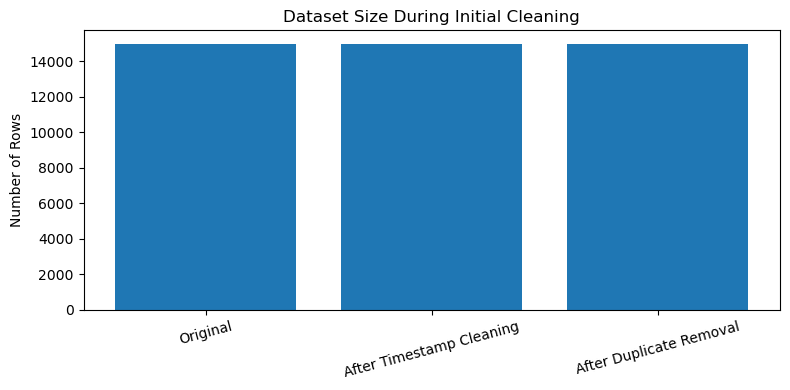

In [16]:
# Restart from the original dataset
df_clean = df.copy()

# Step 1: Handle invalid timestamps
df_clean["Timestamp"] = pd.to_datetime(
    df_clean["Timestamp"], errors="coerce"
)

original_rows = len(df_clean)
invalid_timestamps = df_clean["Timestamp"].isna().sum()

df_clean = df_clean.dropna(subset=["Timestamp"]).copy()
rows_after_timestamp = len(df_clean)

# Step 2: Count duplicates BEFORE removing them
duplicates_before = df_clean.duplicated().sum()

print("Original rows:", original_rows)
print("Invalid timestamps removed:", invalid_timestamps)
print("Rows after timestamp treatment:", rows_after_timestamp)
print("Duplicate rows BEFORE removal:", duplicates_before)

# Step 3: Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

print("Duplicate rows AFTER removal:", df_clean.duplicated().sum())
print("Duplicate rows removed:", duplicates_before - df_clean.duplicated().sum())
print("Rows after duplicate treatment:", len(df_clean))

# Step 4: Handle missing numerical values
numeric_cols = df_clean.select_dtypes(include="number").columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Final shape:", df_clean.shape)

# Graph: Track row counts during cleaning
plt.figure(figsize=(8, 4))
plt.bar(
    ["Original", "After Timestamp Cleaning", "After Duplicate Removal"],
    [original_rows, rows_after_timestamp, len(df_clean)]
)
plt.title("Dataset Size During Initial Cleaning")
plt.ylabel("Number of Rows")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Invalid observation checks:


,Flagged Observations
Vehicle Speed,4
Ambient Humidity,4
Battery SOC,4
Battery SOH,3
Battery Voltage,2
Battery Temperature,3
Negative Motor RPM,3
Tire Pressure,3
Tire Temperature,2
Component Health Score,2


Total flagged sensor values: 30
Rows with at least one flagged value: 30


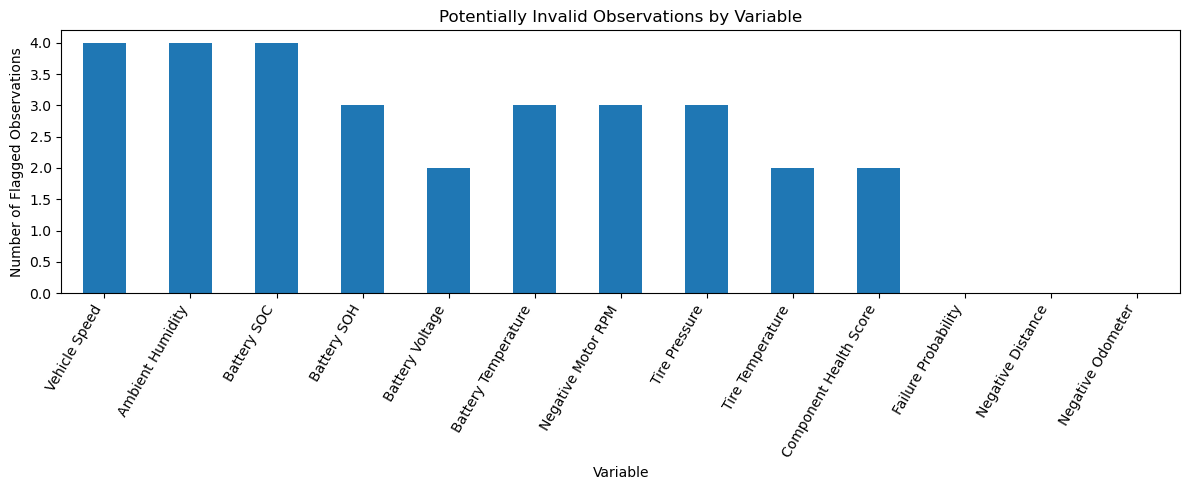

In [18]:
# Check for invalid sensor values
# Do not remove any rows yet

invalid_masks = {
    "Vehicle Speed": df_clean["Vehicle_Speed_kmh"] < 0,

    "Ambient Humidity": ~df_clean["Ambient_Humidity_pct"].between(0, 100),

    "Battery SOC": ~df_clean["Battery_SOC_pct"].between(0, 100),

    "Battery SOH": ~df_clean["Battery_SOH_pct"].between(0, 100),

    "Battery Voltage": (
        (df_clean["Battery_Pack_Voltage_V"] <= 0) |
        (df_clean["Battery_Pack_Voltage_V"] > 450)
    ),

    "Battery Temperature": (
        (df_clean["Battery_Temperature_C"] < -20) |
        (df_clean["Battery_Temperature_C"] > 80)
    ),

    "Negative Motor RPM": df_clean["Motor_RPM"] < 0,

    "Tire Pressure": (
        (df_clean["Tire_Pressure_psi"] <= 0) |
        (df_clean["Tire_Pressure_psi"] > 60)
    ),

    "Tire Temperature": (
        (df_clean["Tire_Temperature_C"] < -20) |
        (df_clean["Tire_Temperature_C"] > 80)
    ),

    "Component Health Score":
        ~df_clean["Component_Health_Score"].between(0, 1),

    "Failure Probability":
        ~df_clean["Failure_Probability_pct"].between(0, 100),

    "Negative Distance":
        df_clean["Distance_Since_Last_Record_km"] < 0,

    "Negative Odometer":
        df_clean["Odometer_km"] < 0
}

# Create summary table
invalid_summary = pd.DataFrame({
    "Flagged Observations": {
        name: int(mask.sum())
        for name, mask in invalid_masks.items()
    }
})

print("Invalid observation checks:")
display(invalid_summary)

# Count unique rows with at least one flagged value
invalid_rows = pd.DataFrame(invalid_masks).any(axis=1).sum()

print("Total flagged sensor values:",
      invalid_summary["Flagged Observations"].sum())

print("Rows with at least one flagged value:", invalid_rows)

# Graph: Flagged observations by variable
plt.figure(figsize=(12, 5))

invalid_summary["Flagged Observations"].plot(kind="bar")

plt.title("Potentially Invalid Observations by Variable")
plt.xlabel("Variable")
plt.ylabel("Number of Flagged Observations")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

Rows containing at least one flagged observation: 30


,Timestamp,Vehicle_ID,Operating_Mode,Vehicle_Speed_kmh,Ambient_Humidity_pct,Battery_SOC_pct,Battery_SOH_pct,Battery_Pack_Voltage_V,Battery_Temperature_C,Motor_RPM,Tire_Pressure_psi,Tire_Temperature_C,Component_Health_Score
5140,2025-02-02 03:00:00,EV_001,Idle,0.00,71.23,40.62,89.24,352.84,110.00,0.0,33.12,22.32,0.8771
8618,2025-02-23 21:00:00,EV_001,Driving,49.66,64.34,34.42,89.34,348.83,30.66,3767.8,32.59,100.00,0.8766
13815,2025-03-28 09:00:00,EV_001,Driving,91.56,61.47,44.42,89.18,355.40,42.39,6568.4,33.37,47.22,1.2000
11398,2025-03-13 06:00:00,EV_002,Driving,-5.00,62.34,30.52,93.27,344.38,39.44,3689.5,34.88,46.45,0.8984
525,2025-01-04 06:00:00,EV_004,Idle,0.00,65.24,112.00,96.76,362.69,26.90,0.0,34.56,23.13,0.9496
6442,2025-02-10 06:00:00,EV_004,Idle,0.00,70.58,36.23,96.59,350.24,27.32,0.0,0.00,25.72,0.9515
13958,2025-03-29 06:00:00,EV_004,Charging,0.00,54.99,35.79,96.43,347.62,34.64,-750.0,33.45,27.00,0.9316
7062,2025-02-14 03:00:00,EV_005,Idle,0.00,63.94,30.16,94.75,344.62,110.00,0.0,34.55,26.92,0.9195
12979,2025-03-23 03:00:00,EV_006,Charging,0.00,56.53,37.29,95.36,350.86,33.76,-300.0,34.64,26.94,0.9210
388,2025-01-03 09:00:00,EV_008,Driving,38.20,110.00,53.02,97.35,364.47,34.54,2808.3,35.20,45.67,0.9502


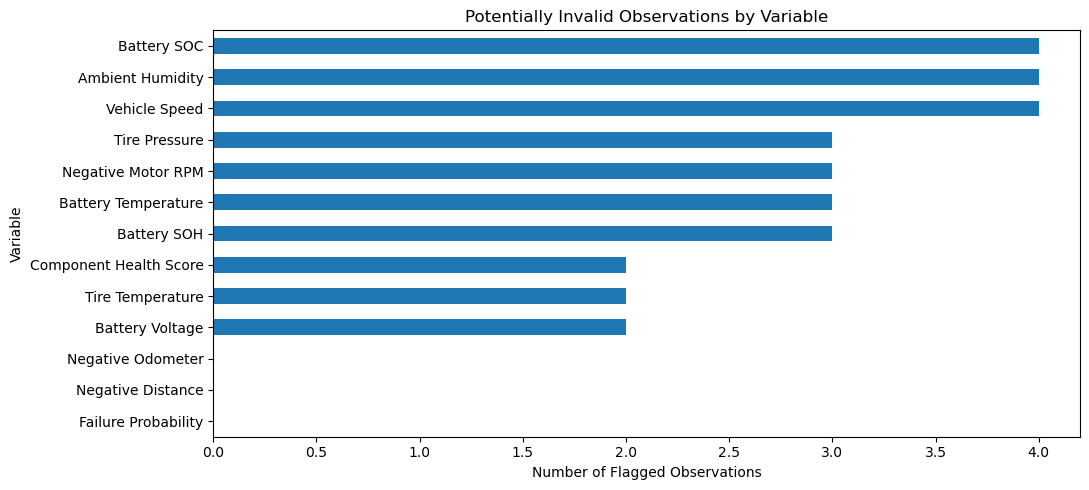

In [19]:
# Identify rows containing at least one flagged observation
flagged_rows = pd.DataFrame(
    invalid_masks, index=df_clean.index
).any(axis=1)

# Select relevant columns for inspection
inspection_cols = [
    "Timestamp",
    "Vehicle_ID",
    "Operating_Mode",
    "Vehicle_Speed_kmh",
    "Ambient_Humidity_pct",
    "Battery_SOC_pct",
    "Battery_SOH_pct",
    "Battery_Pack_Voltage_V",
    "Battery_Temperature_C",
    "Motor_RPM",
    "Tire_Pressure_psi",
    "Tire_Temperature_C",
    "Component_Health_Score"
]

# Display flagged observations
print("Rows containing at least one flagged observation:",
      flagged_rows.sum())

display(
    df_clean.loc[flagged_rows, inspection_cols]
    .sort_values(["Vehicle_ID", "Timestamp"])
)

# Graph: Number of flagged observations by variable
plt.figure(figsize=(11, 5))

invalid_summary["Flagged Observations"].sort_values().plot(
    kind="barh"
)

plt.title("Potentially Invalid Observations by Variable")
plt.xlabel("Number of Flagged Observations")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

,Invalid Values
Vehicle_Speed_kmh,4
Ambient_Humidity_pct,4
Battery_SOC_pct,4
Battery_SOH_pct,3
Battery_Pack_Voltage_V,2
Battery_Temperature_C,3
Motor_RPM,3
Tire_Pressure_psi,3
Tire_Temperature_C,2
Component_Health_Score,2


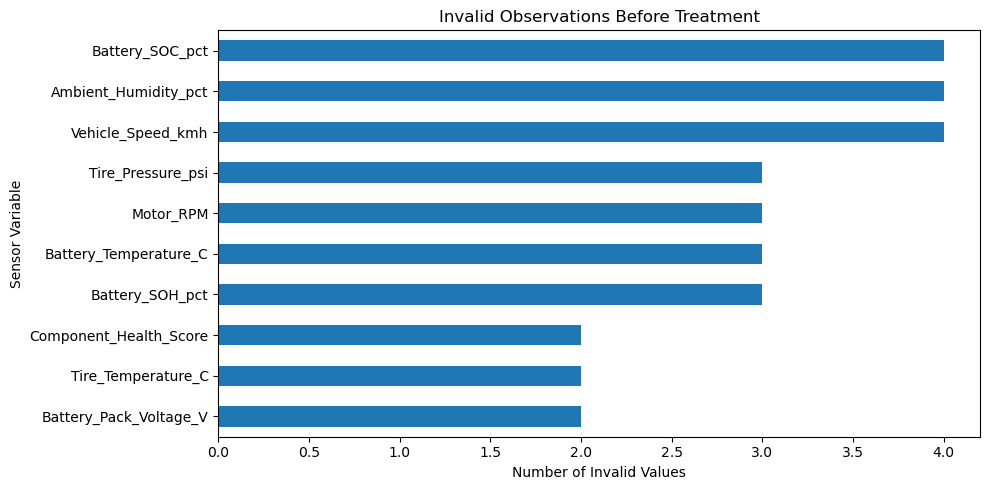

Remaining missing values: 0
Dataset shape: (14971, 29)

Remaining invalid values:
Vehicle_Speed_kmh: 0
Ambient_Humidity_pct: 0
Battery_SOC_pct: 0
Battery_SOH_pct: 0
Battery_Pack_Voltage_V: 0
Battery_Temperature_C: 0
Motor_RPM: 0
Tire_Pressure_psi: 0
Tire_Temperature_C: 0
Component_Health_Score: 0


In [20]:
# Define invalid-value rules
invalid_rules = {
    "Vehicle_Speed_kmh":
        df_clean["Vehicle_Speed_kmh"] < 0,

    "Ambient_Humidity_pct":
        ~df_clean["Ambient_Humidity_pct"].between(0, 100),

    "Battery_SOC_pct":
        ~df_clean["Battery_SOC_pct"].between(0, 100),

    "Battery_SOH_pct":
        ~df_clean["Battery_SOH_pct"].between(0, 100),

    "Battery_Pack_Voltage_V":
        (df_clean["Battery_Pack_Voltage_V"] <= 0) |
        (df_clean["Battery_Pack_Voltage_V"] > 450),

    "Battery_Temperature_C":
        (df_clean["Battery_Temperature_C"] < -20) |
        (df_clean["Battery_Temperature_C"] > 80),

    "Motor_RPM":
        df_clean["Motor_RPM"] < 0,

    "Tire_Pressure_psi":
        (df_clean["Tire_Pressure_psi"] <= 0) |
        (df_clean["Tire_Pressure_psi"] > 60),

    "Tire_Temperature_C":
        (df_clean["Tire_Temperature_C"] < -20) |
        (df_clean["Tire_Temperature_C"] > 80),

    "Component_Health_Score":
        ~df_clean["Component_Health_Score"].between(0, 1)
}

# Summarize invalid observations before treatment
invalid_summary = pd.Series({
    col: int(mask.sum())
    for col, mask in invalid_rules.items()
}, name="Invalid Values")

display(invalid_summary.to_frame())

# Graph: Invalid observations by variable
plt.figure(figsize=(10, 5))
invalid_summary.sort_values().plot(kind="barh")
plt.title("Invalid Observations Before Treatment")
plt.xlabel("Number of Invalid Values")
plt.ylabel("Sensor Variable")
plt.tight_layout()
plt.show()

# Replace invalid sensor values with missing values
for col, mask in invalid_rules.items():
    df_clean.loc[mask, col] = np.nan

# Fill missing numerical values using column medians
numeric_cols = df_clean.select_dtypes(include="number").columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Verify treatment
print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Dataset shape:", df_clean.shape)

# Check the specified limits again
print("\nRemaining invalid values:")

for col, condition in {
    "Vehicle_Speed_kmh": df_clean["Vehicle_Speed_kmh"] < 0,
    "Ambient_Humidity_pct": ~df_clean["Ambient_Humidity_pct"].between(0, 100),
    "Battery_SOC_pct": ~df_clean["Battery_SOC_pct"].between(0, 100),
    "Battery_SOH_pct": ~df_clean["Battery_SOH_pct"].between(0, 100),
    "Battery_Pack_Voltage_V": (
        (df_clean["Battery_Pack_Voltage_V"] <= 0) |
        (df_clean["Battery_Pack_Voltage_V"] > 450)
    ),
    "Battery_Temperature_C": (
        (df_clean["Battery_Temperature_C"] < -20) |
        (df_clean["Battery_Temperature_C"] > 80)
    ),
    "Motor_RPM": df_clean["Motor_RPM"] < 0,
    "Tire_Pressure_psi": (
        (df_clean["Tire_Pressure_psi"] <= 0) |
        (df_clean["Tire_Pressure_psi"] > 60)
    ),
    "Tire_Temperature_C": (
        (df_clean["Tire_Temperature_C"] < -20) |
        (df_clean["Tire_Temperature_C"] > 80)
    ),
    "Component_Health_Score":
        ~df_clean["Component_Health_Score"].between(0, 1)
}.items():
    print(f"{col}: {condition.sum()}")

,Column,Lower Limit,Upper Limit,Below Limit,Above Limit,Total Outliers
17,Regenerative_Braking_Power_kW,-1.245,2.075,0,2255,2255
16,Brake_Pressure_bar,-3.095,6.065,0,1454,1454
15,Motor_Vibration_g,-0.023,0.249,0,525,525
5,Battery_SOC_pct,5.890,63.650,0,391,391
8,Battery_Pack_Voltage_V,324.878,371.178,0,388,388
20,Battery_Power_kW,-40.768,69.652,0,307,307
22,Failure_Probability_pct,-2.900,12.220,0,302,302
9,Battery_Pack_Current_A,-120.120,201.880,0,296,296
13,Motor_Power_kW,-39.128,65.213,0,270,270
14,Motor_Temperature_C,15.252,79.872,0,201,201


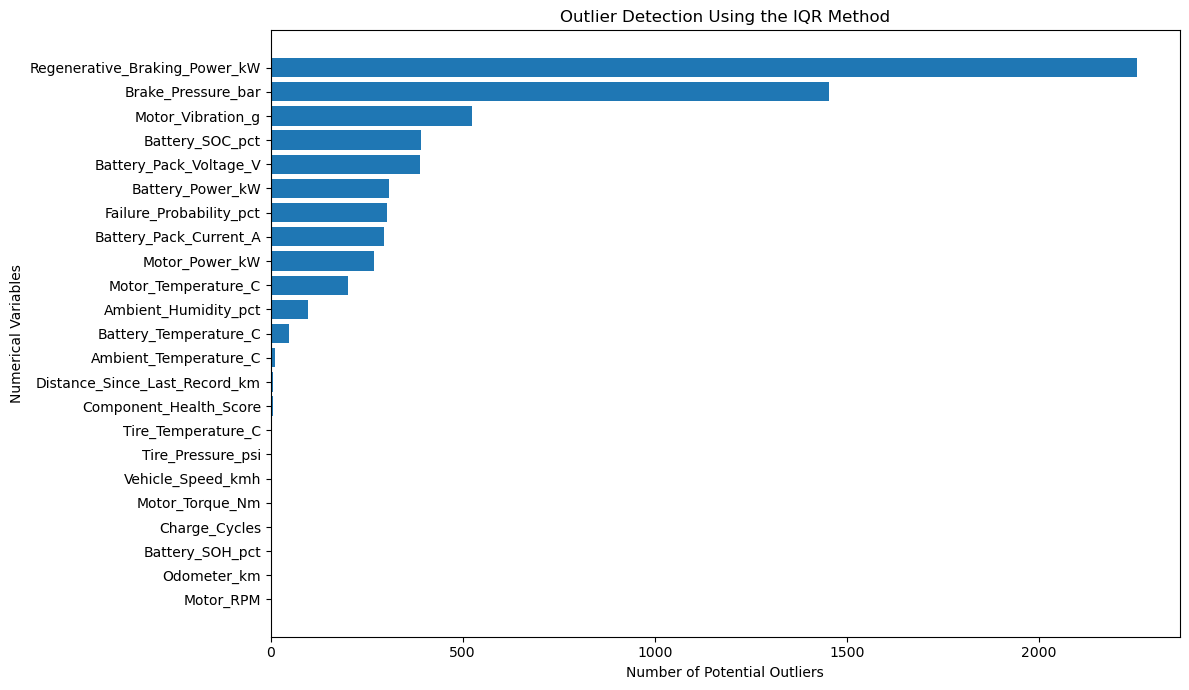

In [21]:
# Detect outliers without removing any rows

numeric_cols = df_clean.select_dtypes(include="number").columns

outlier_summary = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    below = (df_clean[col] < lower_limit).sum()
    above = (df_clean[col] > upper_limit).sum()

    outlier_summary.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Below Limit": below,
        "Above Limit": above,
        "Total Outliers": below + above
    })

outlier_df = pd.DataFrame(outlier_summary)

# Display outlier summary
outlier_df = outlier_df.sort_values(
    "Total Outliers", ascending=False
)

display(outlier_df.round(3))

# Graph: Outliers by numerical column
plt.figure(figsize=(12, 7))

plt.barh(
    outlier_df["Column"],
    outlier_df["Total Outliers"]
)

plt.title("Outlier Detection Using the IQR Method")
plt.xlabel("Number of Potential Outliers")
plt.ylabel("Numerical Variables")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Important: No observations are removed in this step.

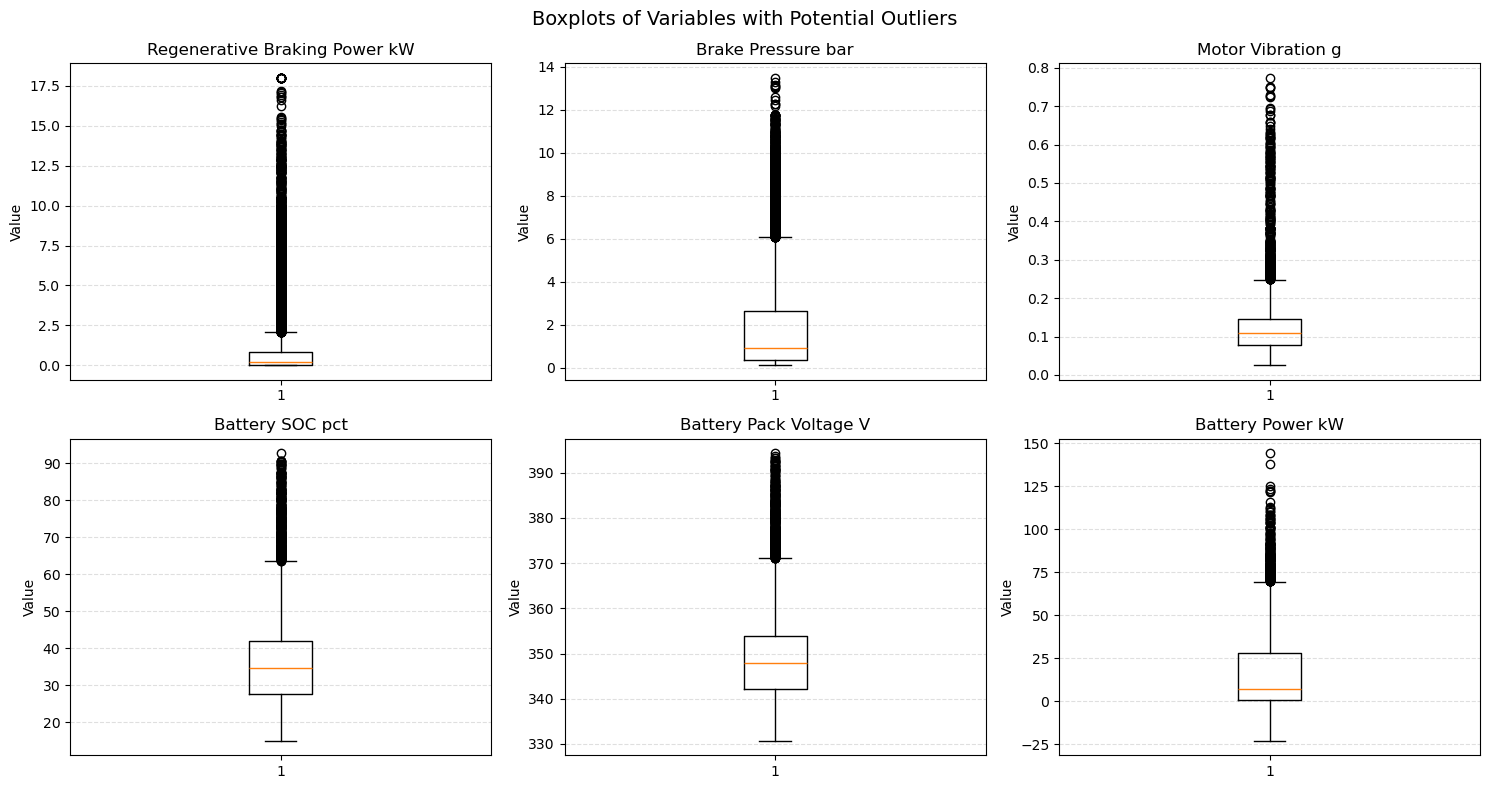

In [22]:
# Objective 2 — Step 9: Visualize potential outliers using boxplots
# This step only visualizes the data; no rows are removed.

outlier_cols = [
    "Regenerative_Braking_Power_kW",
    "Brake_Pressure_bar",
    "Motor_Vibration_g",
    "Battery_SOC_pct",
    "Battery_Pack_Voltage_V",
    "Battery_Power_kW"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flatten(), outlier_cols):
    ax.boxplot(df_clean[col].dropna(), vert=True)
    ax.set_title(col.replace("_", " "))
    ax.set_ylabel("Value")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.suptitle("Boxplots of Variables with Potential Outliers", fontsize=14)
plt.tight_layout()
plt.show()

,Column,Lower Limit,Upper Limit,Outliers Flagged
0,Regenerative_Braking_Power_kW,-1.245,2.075,2255
1,Brake_Pressure_bar,-3.095,6.065,1454
2,Motor_Vibration_g,-0.023,0.249,525
3,Battery_SOC_pct,5.890,63.650,391
4,Battery_Pack_Voltage_V,324.878,371.178,388
5,Battery_Power_kW,-40.768,69.652,307


Rows with at least one flagged measurement: 3193
Rows retained in df_clean: 14971


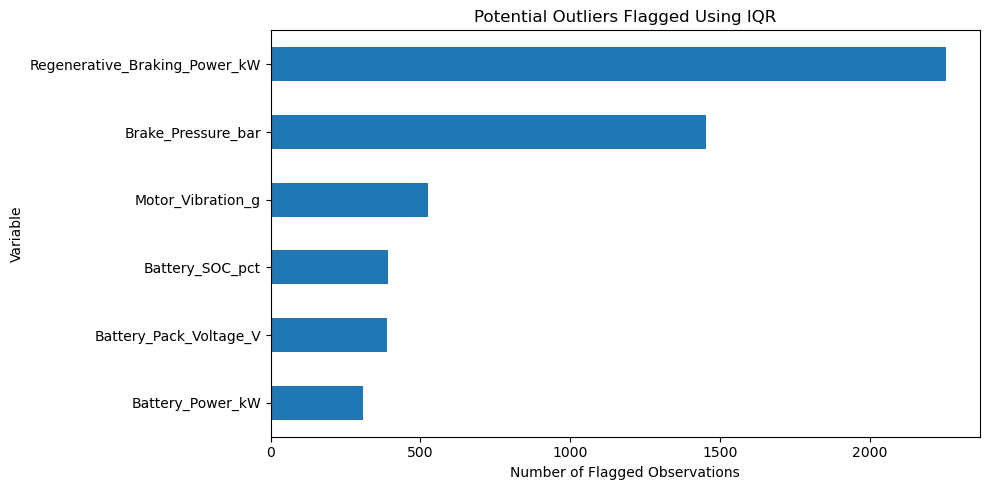

In [30]:
# Flag potential IQR outliers without changing df_clean

outlier_cols = [
    "Regenerative_Braking_Power_kW",
    "Brake_Pressure_bar",
    "Motor_Vibration_g",
    "Battery_SOC_pct",
    "Battery_Pack_Voltage_V",
    "Battery_Power_kW"
]

outlier_flags = pd.DataFrame(index=df_clean.index)
outlier_summary = []

for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    # Identify potential outliers
    mask = (
        (df_clean[col] < lower_limit) |
        (df_clean[col] > upper_limit)
    )

    # Store flags separately; do not remove or modify readings
    outlier_flags[col + "_IQR_Flag"] = mask

    outlier_summary.append({
        "Column": col,
        "Lower Limit": lower_limit,
        "Upper Limit": upper_limit,
        "Outliers Flagged": int(mask.sum())
    })

# Display results
outlier_summary = pd.DataFrame(outlier_summary)
display(outlier_summary.round(3))

# Count rows having at least one flagged measurement
any_outlier = outlier_flags.any(axis=1)

print(
    "Rows with at least one flagged measurement:",
    int(any_outlier.sum())
)

print("Rows retained in df_clean:", len(df_clean))

# Graph: Number of flagged outliers by variable
plt.figure(figsize=(10, 5))

outlier_summary.set_index("Column")["Outliers Flagged"].sort_values().plot(
    kind="barh"
)

plt.title("Potential Outliers Flagged Using IQR")
plt.xlabel("Number of Flagged Observations")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()